# 🏎️ Trabajo Final Integrador
## Rendimiento de las escuderías de Fórmula 1 (2017-2025): análisis exploratorio en Python



## 1. Planteo del caso y selección del dataset

### 1.1 Contexto
En la Fórmula 1 cada escudería compite durante toda la temporada por puntos, y en cada carrera influyen la posición de largada, la confiabilidad del auto y las condiciones de la pista.
Este proyecto analiza qué escuderías rindieron mejor entre 2017 y 2025 y qué factores se relacionan con esos resultados.

### 1.2 Pregunta principal
**¿Cómo evolucionó el rendimiento de las escuderías de Fórmula 1 entre 2017 y 2025 (puntos y abandonos) y qué factores se relacionan con los mejores resultados?**

### 1.3 Subpreguntas
- **KPI 1:** ¿Qué escuderías acumularon más puntos, en total y en cada temporada?
- **KPI 2:** ¿Qué porcentaje de las participaciones terminó en abandono y cómo cambió por temporada?
- **KPI 3:** ¿Cuántas posiciones ganan o pierden en promedio las escuderías entre la largada y la llegada, y qué tanto influye la posición de largada?

### 1.4 Dataset elegido
Tabla de Fórmula 1 con **una fila por vuelta de cada piloto en cada Gran Premio**, de la temporada 2017 a la 2025.

- **Tamaño:** más de 233.000 filas y 34 columnas
- **Origen:** tabla armada para el curso a partir de datos aproximados de pilotos, escuderías, circuitos y fechas de la F1. Los tiempos, posiciones, puntos y condiciones de carrera son **sintéticos** y el archivo incluye errores a propósito (duplicados, vacíos, textos inconsistentes, formatos de fecha mezclados y valores fuera de rango) para practicar la limpieza.


### 1.5 Justificación y viabilidad
- **Cantidad de registros:** más de 233.000 filas, dentro del rango recomendado (10.000 a 2 millones).
- **Cantidad de columnas:** 34, dentro del rango pedido (5 a 60 columnas útiles tras la limpieza).
- **Variedad de datos:** numéricas (tiempos, velocidades, puntos), categóricas (escudería, piloto, clima, neumático), fechas y booleanas.
- **Viabilidad de las preguntas:** las tres se pueden responder con las columnas disponibles. La 1 con la suma de `puntos` por `escuderia` y `temporada`, la 2 con el promedio de `abandono`, y la 3 con la diferencia entre `posicion_largada` y `posicion_final`.
- **Calidad de datos:** el dataset tiene problemas típicos de datos reales, lo que permite aplicar y documentar todo el proceso de auditoría y limpieza.

## 2. Ingesta de datos

### 2.1 Importar librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")     # estilo de los gráficos
pd.set_option("display.max_columns", 40)

### 2.2 Leer el dataset

In [ ]:
data_set = pd.read_csv("/content/f1_tabla_grande.csv")
data_set.shape

/tmp/ipykernel_438/3965916910.py:1: DtypeWarning: Columns (21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  data_set = pd.read_csv("/content/f1_tabla_grande.csv")


(49934, 34)

## 3. Auditoría de calidad de datos (diagnóstico)

### 3.1 Estructura general

In [ ]:
data_set.head(10)

,id_registro,campeonato,temporada,ronda,fecha,gran_premio,circuito,pais,longitud_circuito_km,piloto,nacionalidad,numero_auto,escuderia,vuelta,tiempo_vuelta_s,sector1_s,sector2_s,sector3_s,velocidad_maxima_kmh,neumatico,edad_neumatico,parada_en_boxes,vuelta_rapida,clima,temp_pista_c,temp_aire_c,humedad_pct,combustible_kg,posicion_largada,posicion_final,puntos,vueltas_completadas,estado_carrera,abandono
0,1,Formula 1,2020,3,2020-06-28,Austrian Grand Prix,Red Bull Ring,Austria,4.318,Esteban Ocon,French,9,Renault,47,67.604,20.895,25.020,21.689,341.5,Soft,47.0,False,False,cloudy,NaN,6.0,81.5,35.01,4.0,8.0,4.0,71.0,finished,No
1,2,Formula 1,2023,18,2023-11-05,United States Grand Prix,CIRCUIT OF THE AMERICAS,USA,5.513,Max Verstappen,Dutch,37,Red Bull Racing,20,91.749,NaN,33.936,29.375,313.7,hard,5.0,False,False,Seco,41.1,34.1,44.4,67.58,1.0,1.0,25.0,55.0,Finished,NO
2,3,Formula 1,2017,1,2017-03-19,Australian Grand Prix,Albert Park Circuit,Australia,5.303,Sergio Peres,Mexican,38,Sahara Force India,35,92.530,28.686,34.387,29.458,319.4,medium,17.0,False,False,dry,42.3,33.3,33.7,42.05,11.0,11.0,0.0,58.0,FINISHED,no
3,4,Formula 1,2023,12,27/08/2023,Belgian Grand Prix,Circuit de Spa-Francorchamps,Belgium,7.004,Nico Hulkenberg,German,51,Haas F1 Team,20,104.108,32.355,38.647,33.106,346.6,soft,20.0,False,False,dry,40.3,29.6,52.8,56.42,19.0,14.0,0.0,44.0,Finished,NO
4,5,Formula 1,2017,15,2017-10-01,MALAYSIAN GRAND PRIX,Sepang International Circuit,Malaysia,5.543,Romain Grosjean,french,65,Haas,13,96.277,29.896,35.600,30.782,338.6,SOFT,13.0,False,False,dry,45.6,36.0,30.2,79.52,12.0,12.0,0.0,55.0,Finished,No
5,6,Formula 1,2021,18,2021-10-31,Mexico City Grand Prix,Autodromo Hermanos Rodriguez,Mexico,4.304,Daniel Ricciardo,Australian,69,McLaren,14,72.480,22.286,26.677,23.517,322.0,Medium,14.0,False,False,DRY,38.4,32.8,35.9,84.12,13.0,17.0,0.0,70.0,+1 Lap,No
6,7,Formula 1,2020,3,2020-06-28,Austrian Grand Prix,Red Bull Ring,AUSTRIA,4.318,Sergio Perez,Mexican,85,Racing Point,33,66.458,20.677,24.526,21.255,332.3,Hard,7.0,False,False,Cloudy,12.9,5.7,83.6,55.89,17.0,21.0,0.0,70.0,+1 Lap,NO
7,8,Formula 1,2021,12,2021-08-29,Belgian Grand Prix,Circuit de Spa-Francorchamps,Belgium,7.004,Lance Stroll,Canadian,53,Aston Martin,34,106.214,32.817,39.350,NaN,334.7,hard,4.0,False,False,Seco,43.6,31.6,35.3,24.13,4.0,7.0,6.0,44.0,Finished,NO
8,9,Formula 1,2020,17,06/12/2020,Sakhir Grand Prix,Bahrain International Circuit,Bahrain,3.543,Lance Stroll,Canadian,1,Racing Point,11,62.186,19.248,23.082,19.857,330.9,INTERMEDIATE,11.0,False,False,mixed,25.5,17.4,68.5,91.87,NaN,14.0,0.0,86.0,Finished,no
9,10,Formula 1,2025,6,2025-05-11,Spanish Grand Prix,Circuit de Barcelona-Catalunya,Spain,4.655,Esteban Ocon,FRENCH,48,Haas F1 Team,12,75.700,23.436,28.039,24.225,331.4,Medium,12.0,False,False,DRY,36.2,27.0,33.3,86.33,18.0,15.0,0.0,66.0,Finished,no


In [ ]:
data_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49934 entries, 0 to 49933
Data columns (total 34 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_registro           49934 non-null  int64  
 1   campeonato            49934 non-null  object 
 2   temporada             49934 non-null  int64  
 3   ronda                 49934 non-null  int64  
 4   fecha                 49192 non-null  object 
 5   gran_premio           49670 non-null  object 
 6   circuito              49432 non-null  object 
 7   pais                  49685 non-null  object 
 8   longitud_circuito_km  48923 non-null  float64
 9   piloto                49448 non-null  object 
 10  nacionalidad          48965 non-null  object 
 11  numero_auto           49934 non-null  int64  
 12  escuderia             49446 non-null  object 
 13  vuelta                49934 non-null  int64  
 14  tiempo_vuelta_s       48965 non-null  float64
 15  sector1_s          

In [ ]:
data_set.describe().T

,count,mean,std,min,25%,50%,75%,max
id_registro,49934.0,26828.459286,23153.495333,1.0,12398.250,24808.500,37189.750,226118.0
temporada,49934.0,2021.203489,2.610655,2017.0,2019.000,2021.000,2024.000,2025.0
ronda,49934.0,11.243642,6.306775,1.0,6.000,11.000,17.000,24.0
longitud_circuito_km,48923.0,5.543630,22.499186,-1.0,4.318,5.245,5.793,999.9
numero_auto,49934.0,49.788220,27.604246,1.0,26.000,50.000,72.000,99.0
vuelta,49934.0,30.837145,18.435151,1.0,15.000,30.000,45.000,86.0
tiempo_vuelta_s,48965.0,96.914497,265.160429,-1.0,80.760,89.841,96.894,9999.0
sector1_s,48457.0,35.258491,271.712704,-1.0,25.035,27.859,30.047,9999.0
sector2_s,48321.0,38.405965,226.674374,-1.0,29.886,33.244,35.866,9999.0
sector3_s,48438.0,34.301222,235.368340,-1.0,25.854,28.748,31.009,9999.0


**Qué observo:**
- El dataset tiene **232.932 filas y 34 columnas**.
- Cada fila es una vuelta de un piloto en una carrera, así que datos como la posición final o los puntos se repiten en todas las vueltas.
- El `describe()` muestra valores imposibles en casi todas las mediciones: la longitud del circuito llega a **-1 y a 999,9 km**, los tiempos de vuelta a **-1 y 9999 s**, la velocidad máxima a **0 y 3.120 km/h**, las temperaturas a **-999 y 999 °C**, la humedad a **250 %**, las posiciones a **0 y 99** y los puntos de **-10 a 250**.

### 3.2 Tipos de datos

In [ ]:
data_set.dtypes

,0
id_registro,int64
campeonato,object
temporada,int64
ronda,int64
fecha,object
gran_premio,object
circuito,object
pais,object
longitud_circuito_km,float64
piloto,object


In [ ]:
# Cantidad de columnas de cada tipo
data_set.dtypes.value_counts()

,count
float64,15
object,14
int64,5


**Qué observo:** hay 15 columnas `float64` (mediciones y resultados, decimales porque tienen vacíos), 5 `int64` (`id_registro`, `temporada`, `ronda`, `numero_auto` y `vuelta`), 2 `bool` (`parada_en_boxes` y `vuelta_rapida`) y 12 de texto (`object` en Colab).
Tienen un tipo inadecuado:
- `fecha` está como texto y debería ser de tipo fecha.
- `abandono` está como texto (`Si` / `No`) y debería ser numérica o booleana.

### 3.3 Valores nulos

In [ ]:
nulos = data_set.isna().sum()
porcentaje = (data_set.isna().mean() * 100).round(2)

tabla_nulos = pd.DataFrame({"nulos": nulos, "porcentaje (%)": porcentaje})
tabla_nulos[tabla_nulos["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,porcentaje (%)
combustible_kg,2015,4.04
sector2_s,1613,3.23
vueltas_completadas,1517,3.04
posicion_final,1511,3.03
edad_neumatico,1506,3.02
puntos,1500,3.00
sector3_s,1496,3.00
humedad_pct,1494,2.99
posicion_largada,1481,2.97
sector1_s,1477,2.96


**Qué observo:** hay vacíos en **26 de las 34 columnas** (130.854 celdas vacías en total).
- La que más tiene es `combustible_kg` (4,03 %).
- Alrededor del 3 % tienen los sectores, la humedad, la edad del neumático, las posiciones, los puntos y las vueltas completadas.
- Alrededor del 2 % tienen el tiempo de vuelta, la velocidad, las temperaturas, el clima, el neumático, el estado de la carrera y el abandono.
- `fecha` tiene 1,43 %, y `piloto` y `escuderia` tienen cerca del 1 %.
- No tienen vacíos `id_registro`, `campeonato`, `temporada`, `ronda`, `numero_auto`, `vuelta`, `parada_en_boxes` ni `vuelta_rapida`.

### 3.4 Filas duplicadas

In [ ]:
print("Filas duplicadas:", data_set.duplicated().sum())
print("Porcentaje del total:", round(data_set.duplicated().mean() * 100, 2), "%")

# Algunas filas duplicadas, ordenadas por id para verlas juntas
data_set[data_set.duplicated(keep=False)].sort_values("id_registro").head(6)

Filas duplicadas: 346
Porcentaje del total: 0.69 %


,id_registro,campeonato,temporada,ronda,fecha,gran_premio,circuito,pais,longitud_circuito_km,piloto,nacionalidad,numero_auto,escuderia,vuelta,tiempo_vuelta_s,sector1_s,sector2_s,sector3_s,velocidad_maxima_kmh,neumatico,edad_neumatico,parada_en_boxes,vuelta_rapida,clima,temp_pista_c,temp_aire_c,humedad_pct,combustible_kg,posicion_largada,posicion_final,puntos,vueltas_completadas,estado_carrera,abandono
121,119,Formula 1,2018,8,2018-06-24,French Grand Prix,Circuit Paul Ricard,France,5.800,Lewis Hamilton,BRITISH,51,Mercedes,46,100.595,31.025,NaN,32.332,334.0,hard,1.0,False,False,dry,45.0,37.4,62.3,14.41,1.0,19.0,0.0,47.0,Gearbox,SI
29173,119,Formula 1,2018,8,2018-06-24,French Grand Prix,Circuit Paul Ricard,France,5.800,Lewis Hamilton,BRITISH,51,Mercedes,46,100.595,31.025,NaN,32.332,334.0,hard,1.0,False,False,dry,45.0,37.4,62.3,14.41,1.0,19.0,0.0,47.0,Gearbox,SI
5078,279,Formula 1,2024,20,2024-11-03,United States Grand Prix,Circuit of the Americas,USA,5.513,Carlos Sainz,Spanish,33,Ferrari,22,92.210,28.415,34.245,29.550,337.3,Soft,22.0,False,False,NaN,48.0,35.8,36.3,63.03,5.0,6.0,8.0,55.0,Finished,No
288,279,Formula 1,2024,20,2024-11-03,United States Grand Prix,Circuit of the Americas,USA,5.513,Carlos Sainz,Spanish,33,Ferrari,22,92.210,28.415,34.245,29.550,337.3,Soft,22.0,False,False,NaN,48.0,35.8,36.3,63.03,5.0,6.0,8.0,55.0,Finished,No
7879,413,Formula 1,2025,14,2025-08-31,Belgian Grand Prix,Circuit de Spa-Francorchamps,belgium,7.004,Esteban Ocon,French,48,HAAS F1 TEAM,35,102.283,31.795,37.911,32.576,335.2,Hard,10.0,False,False,Seco,32.3,20.2,38.3,21.97,20.0,15.0,0.0,44.0,Finished,NaN
428,413,Formula 1,2025,14,2025-08-31,Belgian Grand Prix,Circuit de Spa-Francorchamps,belgium,7.004,Esteban Ocon,French,48,HAAS F1 TEAM,35,102.283,31.795,37.911,32.576,335.2,Hard,10.0,False,False,Seco,32.3,20.2,38.3,21.97,20.0,15.0,0.0,44.0,Finished,NaN


**Qué observo:** hay **6.784 filas duplicadas** (2,91 % del total). Son copias exactas: cada `id_registro` repetido aparece dos veces con todos los valores iguales. Como cada `id_registro` debería ser único, son repeticiones y hay que eliminarlas.

### 3.5 Columnas sin utilidad (varianza nula)

In [ ]:
# Cantidad de valores distintos de cada columna
data_set.nunique().sort_values()

,0
campeonato,1
vuelta_rapida,2
parada_en_boxes,2
abandono,6
temporada,9
puntos,13
clima,14
neumatico,22
posicion_largada,24
posicion_final,24


**Qué observo:** `campeonato` tiene **un solo valor distinto** (`Formula 1`), es decir varianza nula: no aporta información y se puede eliminar.
También hay columnas con muchos más valores distintos de los que deberían tener, lo que indica inconsistencias de escritura: `escuderia` tiene 105 (son 18 escuderías), `piloto` 184 (son 44 pilotos), `estado_carrera` 64 (son 11 estados) y `abandono` 6 (debería tener solo 2).

### 3.6 Inconsistencias en categorías, fechas y unidades

In [ ]:
print("Escuderías distintas:", data_set["escuderia"].nunique())
data_set["escuderia"].value_counts().head(15)

Escuderías distintas: 105


,count
escuderia,
Williams,3907
Red Bull Racing,3831
McLaren,3764
Haas F1 Team,3611
Ferrari,3478
Mercedes,3470
Alpine,2269
Aston Martin,2086
AlphaTauri,1986


In [ ]:
# Ejemplo: distintas formas de escribir al mismo piloto
data_set.loc[data_set["piloto"].str.contains("colapinto", case=False, na=False), "piloto"].value_counts()

,count
piloto,
Franco Colapinto,495
FRANCO COLAPINTO,37
franco colapinto,33
Franco Colapinto,18
Frranco Colapinto,15


In [ ]:
print("Valores distintos de abandono:")
print(data_set["abandono"].value_counts())
print()
print("Valores distintos de estado_carrera:", data_set["estado_carrera"].nunique())

Valores distintos de abandono:
abandono
No    28073
NO     9394
no     9377
Si     1238
si      432
SI      426
Name: count, dtype: int64

Valores distintos de estado_carrera: 64


In [ ]:
# Formatos de fecha
data_set["fecha"].sample(10, random_state=1)

,fecha
38326,2022-04-17
20948,2020-10-11
49840,06/05/2018
32209,2022-09-25
4771,2022-03-27
35434,NaN
6981,2020-09-13
36825,2023-05-07
8051,2022-05-08
9461,2023-11-26


**Qué observo:**
- **`escuderia`:** el mismo equipo está escrito de varias formas: mayúsculas (`FERRARI`), minúsculas (`ferrari`), espacios de más y nombres alternativos o con errores (`Red Bull`, `Haas`, `Ferari`, `Willliams`).
- **`piloto`:** pasa lo mismo. Franco Colapinto aparece como `franco colapinto`, `FRANCO COLAPINTO`, ` Franco Colapinto ` y `Frranco Colapinto`.
- **`abandono`:** aparece como `Si`, `SI`, `si`, `No`, `NO` y `no`.
- **`fecha`:** hay tres formatos mezclados (`2025-09-21`, `21/09/2025` y `21-09-2025`).
- **`clima`, `neumatico` y `estado_carrera`:** tienen sinónimos y abreviaturas (`Seco` y `Dry`, `S` y `Soft`, `Dnf` y `Retired`).
- **Unidades:** todas las columnas numéricas están en la misma unidad (segundos, km/h, °C, %, kg y km), no hay unidades mezcladas.

### 3.7 Valores atípicos (outliers)

In [ ]:
columnas_numericas = ["longitud_circuito_km", "tiempo_vuelta_s", "sector1_s", "sector2_s", "sector3_s",
                      "velocidad_maxima_kmh", "edad_neumatico", "temp_pista_c", "temp_aire_c", "humedad_pct",
                      "combustible_kg", "posicion_largada", "posicion_final", "puntos"]

# Mínimo y máximo de cada columna numérica
data_set[columnas_numericas].describe().T[["min", "max"]]

,min,max
longitud_circuito_km,-1.0,999.9
tiempo_vuelta_s,-1.0,9999.0
sector1_s,-1.0,9999.0
sector2_s,-1.0,9999.0
sector3_s,-1.0,9999.0
velocidad_maxima_kmh,0.0,3120.0
edad_neumatico,-1.0,999.0
temp_pista_c,-999.0,999.0
temp_aire_c,-999.0,999.0
humedad_pct,-1.0,250.0


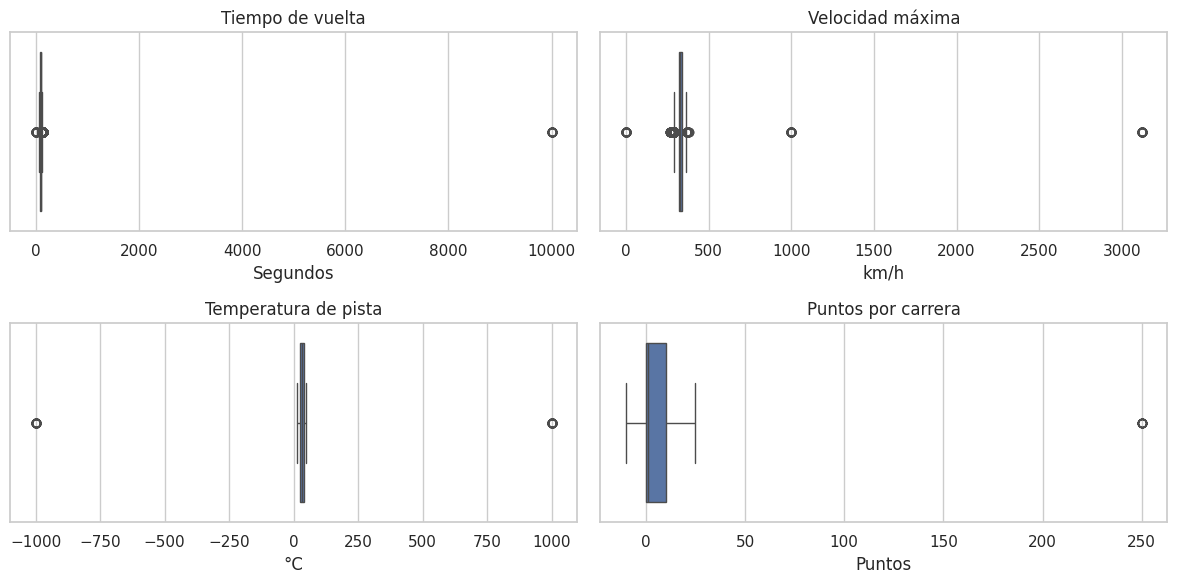

In [ ]:
plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
sns.boxplot(x=data_set["tiempo_vuelta_s"])
plt.title("Tiempo de vuelta")
plt.xlabel("Segundos")

plt.subplot(2, 2, 2)
sns.boxplot(x=data_set["velocidad_maxima_kmh"])
plt.title("Velocidad máxima")
plt.xlabel("km/h")

plt.subplot(2, 2, 3)
sns.boxplot(x=data_set["temp_pista_c"])
plt.title("Temperatura de pista")
plt.xlabel("°C")

plt.subplot(2, 2, 4)
sns.boxplot(x=data_set["puntos"])
plt.title("Puntos por carrera")
plt.xlabel("Puntos")

plt.tight_layout()
plt.show()

Para decidir qué valores son anómalos usé un **criterio objetivo**: un rango válido para cada columna, basado en el reglamento y en la física de las carreras.

| Columna | Rango válido | Justificación |
|---|---|---|
| `longitud_circuito_km` | 2 a 8 | los circuitos miden entre 3 y 7 km |
| `tiempo_vuelta_s` | 50 a 250 | una vuelta no dura menos de un minuto ni más de 4 minutos |
| `sector1_s`, `sector2_s`, `sector3_s` | 5 a 100 | cada sector es una parte de la vuelta |
| `velocidad_maxima_kmh` | 200 a 400 | velocidades posibles de un auto de F1 |
| `edad_neumatico` | 0 a 80 | vueltas que puede durar un juego de neumáticos |
| `temp_pista_c` | 5 a 70 | temperaturas posibles de una pista |
| `temp_aire_c` | -5 a 60 | temperaturas posibles del aire |
| `humedad_pct` | 5 a 100 | es un porcentaje |
| `combustible_kg` | 0,1 a 110 | el tanque máximo es de 110 kg |
| `posicion_largada`, `posicion_final` | 1 a 22 | la grilla tiene como máximo 22 autos |
| `puntos` | 0 a 25 | el ganador de una carrera suma 25 |

In [ ]:
# Cuántos valores quedan fuera del rango en algunas columnas clave
print("Puntos fuera de rango:", ((data_set["puntos"] < 0) | (data_set["puntos"] > 25)).sum())
print("Posiciones de largada fuera de rango:", ((data_set["posicion_largada"] < 1) | (data_set["posicion_largada"] > 22)).sum())
print("Tiempos de vuelta fuera de rango:", ((data_set["tiempo_vuelta_s"] < 50) | (data_set["tiempo_vuelta_s"] > 250)).sum())

Puntos fuera de rango: 38
Posiciones de largada fuera de rango: 40
Tiempos de vuelta fuera de rango: 99


**Qué observo:** hay valores fuera de rango en las 14 columnas numéricas de medición. Por ejemplo, **216 filas con puntos** fuera de 0 a 25, **214 posiciones de largada** fuera de 1 a 22 y **479 tiempos de vuelta** fuera de 50 a 250 s.
Se muestran valores extremos (9999 s, 3.120 km/h, 250 puntos) que aplastan la caja, y el `min` y el `max` del `describe()` confirman el problema. Como el reglamento y la física dan un rango válido para cada columna, uso ese criterio para decidir qué es un error.

## 4. Limpieza y preparación de datos

Voy a aplicar las correcciones en el mismo orden del diagnóstico y guardar el resultado en `data_set_limpio`.
Trabajo sobre una copia para no perder el dataset original.

In [ ]:
data_set_limpio = data_set.copy()
print("Filas al empezar:", len(data_set_limpio))

Filas al empezar: 49934


#### Paso 1: eliminar duplicados
Cada `id_registro` debería aparecer una sola vez. Las filas duplicadas son copias exactas, y si las dejo se cuentan dos veces las vueltas, los puntos y los abandonos.

In [ ]:
data_set_limpio = data_set_limpio.drop_duplicates()
print("Filas después de eliminar duplicados:", len(data_set_limpio))

Filas después de eliminar duplicados: 49588


#### Paso 2: eliminar la columna sin utilidad
`campeonato` vale siempre `Formula 1`, así que no aporta información para comparar filas.

In [ ]:
data_set_limpio = data_set_limpio.drop(columns=["campeonato"])
print("Columnas:", data_set_limpio.shape[1])

Columnas: 33


#### Paso 3: unificar el texto
Saco los espacios de los extremos y dejo la primera letra de cada palabra en mayúscula, para que `FERRARI`, `ferrari` y ` Ferrari ` sean el mismo valor.

In [ ]:
columnas_texto = ["gran_premio", "circuito", "pais", "piloto", "nacionalidad",
                  "escuderia", "neumatico", "clima", "estado_carrera"]

for columna in columnas_texto:
    data_set_limpio[columna] = data_set_limpio[columna].str.strip().str.title()

data_set_limpio["escuderia"].value_counts().head(10)

,count
escuderia,
Williams,4906
Red Bull Racing,4784
Mclaren,4672
Haas F1 Team,4526
Ferrari,4349
Mercedes,4325
Alpine,2835
Aston Martin,2626
Alphatauri,2475


#### Paso 4: unificar las categorías
Después del paso anterior todavía hay nombres distintos para lo mismo (`Red Bull` y `Red Bull Racing`, `Ferari` y `Ferrari`, `Seco` y `Dry`...). Los corrijo con `replace`.

In [ ]:
data_set_limpio["escuderia"] = data_set_limpio["escuderia"].replace({
    "Mclaren": "McLaren",
    "Red Bull": "Red Bull Racing",
    "Mercedes-Amg": "Mercedes",
    "Scuderia Ferrari": "Ferrari",
    "Ferari": "Ferrari",
    "Astonmartin": "Aston Martin",
    "Alpine F1 Team": "Alpine",
    "Williams Racing": "Williams",
    "Willliams": "Williams",
    "Haas": "Haas F1 Team",
    "Kick-Sauber": "Kick Sauber",
    "Alfa Romeo Racing": "Alfa Romeo",
    "Alpha Tauri": "AlphaTauri",
    "Alphatauri": "AlphaTauri",
    "Rb": "RB",
    "Vcarb": "RB",
    "Scuderia Toro Rosso": "Toro Rosso",
    "Renault F1": "Renault",
    "Sahara Force India": "Force India",
})

data_set_limpio["piloto"] = data_set_limpio["piloto"].replace({
    "Max Verstapen": "Max Verstappen",
    "Lewis Hamliton": "Lewis Hamilton",
    "Charles Leclerk": "Charles Leclerc",
    "Frranco Colapinto": "Franco Colapinto",
    "Fernando Alonzo": "Fernando Alonso",
    "Sergio Peres": "Sergio Perez",
    "Lando Noris": "Lando Norris",
    "George Rusell": "George Russell",
})

data_set_limpio["pais"] = data_set_limpio["pais"].replace({"Usa": "USA", "Uae": "UAE"})

data_set_limpio["estado_carrera"] = data_set_limpio["estado_carrera"].replace({
    "Fin": "Finished", "Lapped": "+1 Lap", "Dnf": "Retired", "Crash": "Accident",
    "Engine Failure": "Engine", "Transmission": "Gearbox", "Brake Failure": "Brakes",
    "Spin": "Spun Off", "Dsq": "Disqualified",
})

data_set_limpio["neumatico"] = data_set_limpio["neumatico"].replace({
    "S": "Soft", "Blando": "Soft", "M": "Medium", "Medio": "Medium",
    "H": "Hard", "Duro": "Hard", "Inter": "Intermediate", "Lluvia": "Wet",
})

data_set_limpio["clima"] = data_set_limpio["clima"].replace({
    "Seco": "Dry", "Nublado": "Cloudy", "Rain": "Wet", "Lluvia": "Wet", "Variable": "Mixed",
})

print("Escuderías distintas:", data_set_limpio["escuderia"].nunique())
print("Pilotos distintos:", data_set_limpio["piloto"].nunique())
print("Estados de carrera:", data_set_limpio["estado_carrera"].nunique())

Escuderías distintas: 18
Pilotos distintos: 44
Estados de carrera: 11


#### Paso 5: estandarizar fechas y convertir tipos
- `fecha` está como texto y en tres formatos (`2025-03-16`, `16/03/2025` y `16-03-2025`): convierto cada formato por separado y después los junto en una sola columna de tipo fecha.
- `abandono` está como texto (`Si`, `SI`, `no`...): la paso a número (`1` = abandonó, `0` = terminó).

In [ ]:
# Convierto cada formato por separado (lo que no coincide queda vacío) y los junto
fecha_formato1 = pd.to_datetime(data_set_limpio["fecha"], format="%Y-%m-%d", errors="coerce")   # 2025-03-16
fecha_formato2 = pd.to_datetime(data_set_limpio["fecha"], format="%d/%m/%Y", errors="coerce")   # 16/03/2025
fecha_formato3 = pd.to_datetime(data_set_limpio["fecha"], format="%d-%m-%Y", errors="coerce")   # 16-03-2025
data_set_limpio["fecha"] = fecha_formato1.fillna(fecha_formato2).fillna(fecha_formato3)

data_set_limpio["abandono"] = data_set_limpio["abandono"].str.strip().str.lower()
data_set_limpio["abandono"] = data_set_limpio["abandono"].map({"si": 1, "no": 0})

print(data_set_limpio[["fecha", "abandono"]].dtypes)
print("Fechas vacías después de convertir (ya venían vacías):", data_set_limpio["fecha"].isna().sum())

fecha       datetime64[ns]
abandono           float64
dtype: object
Fechas vacías después de convertir (ya venían vacías): 737


#### Paso 6: corregir los valores fuera de rango
Los valores fuera del rango válido (tabla de la sección 3.7) son errores de carga. No sé cuál era el valor correcto, así que los convierto en vacíos (`NaN`) y los trato junto con el resto de los nulos.

In [ ]:
rangos = {
    "longitud_circuito_km": (2, 8),
    "tiempo_vuelta_s": (50, 250),
    "sector1_s": (5, 100),
    "sector2_s": (5, 100),
    "sector3_s": (5, 100),
    "velocidad_maxima_kmh": (200, 400),
    "edad_neumatico": (0, 80),
    "temp_pista_c": (5, 70),
    "temp_aire_c": (-5, 60),
    "humedad_pct": (5, 100),
    "combustible_kg": (0.1, 110),
    "posicion_largada": (1, 22),
    "posicion_final": (1, 22),
    "puntos": (0, 25),
}

for columna, (minimo, maximo) in rangos.items():
    fuera = (data_set_limpio[columna] < minimo) | (data_set_limpio[columna] > maximo)
    print(f"{columna:22s} valores fuera de rango: {fuera.sum()}")
    data_set_limpio.loc[fuera, columna] = np.nan

longitud_circuito_km   valores fuera de rango: 60
tiempo_vuelta_s        valores fuera de rango: 99
sector1_s              valores fuera de rango: 98
sector2_s              valores fuera de rango: 73
sector3_s              valores fuera de rango: 96
velocidad_maxima_kmh   valores fuera de rango: 155
edad_neumatico         valores fuera de rango: 47
temp_pista_c           valores fuera de rango: 93
temp_aire_c            valores fuera de rango: 109
humedad_pct            valores fuera de rango: 100
combustible_kg         valores fuera de rango: 99
posicion_largada       valores fuera de rango: 40
posicion_final         valores fuera de rango: 43
puntos                 valores fuera de rango: 38


#### Paso 7: tratar los valores nulos
Cada columna se trata según lo que representa:

- **Datos de la carrera** (`fecha`, `gran_premio`, `circuito`, `pais`, `longitud_circuito_km`): son iguales en todas las filas de una misma carrera. Si falta en una fila, **se recupera de otra fila de la misma carrera**.
- **Datos del piloto** (`nacionalidad`, `escuderia`): se recuperan de otras filas del mismo piloto (y de la misma temporada, en el caso de la escudería).
- **`piloto` y `escuderia`:** si siguen vacíos no puedo saber a quién pertenece la fila, así que **elimino** esas filas.
- **Posiciones, puntos, `abandono` y `estado_carrera`:** se repiten en todas las vueltas de un piloto en una carrera, así que los vacíos se resuelven más adelante, al armar la tabla de resultados.
- **Mediciones por vuelta** (tiempos, sectores, velocidad, combustible, temperaturas, humedad, neumáticos): no se pueden inventar, así que **los dejo vacíos**. Pandas los ignora al calcular promedios y gráficos.

In [ ]:
print("Vacíos antes de reconstruir:")
print(data_set_limpio[["fecha", "gran_premio", "circuito", "pais", "nacionalidad", "escuderia", "piloto"]].isna().sum())

Vacíos antes de reconstruir:
fecha           737
gran_premio     262
circuito        499
pais            246
nacionalidad    966
escuderia       483
piloto          485
dtype: int64


In [ ]:
# Datos de la carrera: se agrupa por temporada + ronda y se toma el primer valor que no está vacío
carrera = ["temporada", "ronda"]
for columna in ["fecha", "gran_premio", "circuito", "pais"]:
    data_set_limpio[columna] = data_set_limpio[columna].fillna(data_set_limpio.groupby(carrera)[columna].transform("first"))

# Longitud del circuito: se completa con la mediana de cada circuito
data_set_limpio["longitud_circuito_km"] = data_set_limpio["longitud_circuito_km"].fillna(
    data_set_limpio.groupby("circuito")["longitud_circuito_km"].transform("median"))

# Datos del piloto
data_set_limpio["nacionalidad"] = data_set_limpio["nacionalidad"].fillna(
    data_set_limpio.groupby("piloto")["nacionalidad"].transform("first"))
data_set_limpio["escuderia"] = data_set_limpio["escuderia"].fillna(
    data_set_limpio.groupby(["piloto", "temporada"])["escuderia"].transform("first"))

In [ ]:
print("Vacíos después de reconstruir:")
print(data_set_limpio[["fecha", "gran_premio", "circuito", "pais", "nacionalidad", "escuderia", "piloto"]].isna().sum())

# Las filas sin piloto o sin escudería no se pueden identificar: se eliminan
antes = len(data_set_limpio)
data_set_limpio = data_set_limpio.dropna(subset=["piloto", "escuderia"])
print(f"Filas eliminadas: {antes - len(data_set_limpio)} ({(antes - len(data_set_limpio)) / antes:.1%})")

data_set_limpio = data_set_limpio.reset_index(drop=True)

Vacíos después de reconstruir:
fecha             0
gran_premio       0
circuito          0
pais              0
nacionalidad     14
escuderia         3
piloto          485
dtype: int64
Filas eliminadas: 485 (1.0%)


#### Paso 8: estandarizar unidades y crear variables nuevas
Todas las columnas numéricas ya están en la misma unidad (segundos, km/h, °C, %, kg y km), así que no hace falta convertir unidades.
Creo dos variables nuevas:
- `vel_media_kmh`: velocidad media de la vuelta = kilómetros del circuito / tiempo de la vuelta (en horas).
- `mes`: mes de la carrera, sacado de la fecha.

In [ ]:
data_set_limpio["vel_media_kmh"] = data_set_limpio["longitud_circuito_km"] / data_set_limpio["tiempo_vuelta_s"] * 3600
data_set_limpio["mes"] = data_set_limpio["fecha"].dt.month

data_set_limpio[["vel_media_kmh", "mes"]].describe()

,vel_media_kmh,mes
count,48055.000000,49103.000000
mean,202.870702,7.466509
std,26.423919,2.634631
min,107.558421,3.000000
25%,193.747580,5.000000
50%,210.079288,7.000000
75%,217.214801,10.000000
max,308.263848,12.000000


### 4.1 Verificación del dataset limpio

In [ ]:
data_set_limpio.head(10)

,id_registro,temporada,ronda,fecha,gran_premio,circuito,pais,longitud_circuito_km,piloto,nacionalidad,numero_auto,escuderia,vuelta,tiempo_vuelta_s,sector1_s,sector2_s,sector3_s,velocidad_maxima_kmh,neumatico,edad_neumatico,parada_en_boxes,vuelta_rapida,clima,temp_pista_c,temp_aire_c,humedad_pct,combustible_kg,posicion_largada,posicion_final,puntos,vueltas_completadas,estado_carrera,abandono,vel_media_kmh,mes
0,1,2020,3,2020-06-28,Austrian Grand Prix,Red Bull Ring,Austria,4.318,Esteban Ocon,French,9,Renault,47,67.604,20.895,25.020,21.689,341.5,Soft,47.0,False,False,Cloudy,NaN,6.0,81.5,35.01,4.0,8.0,4.0,71.0,Finished,0.0,229.939057,6
1,2,2023,18,2023-11-05,United States Grand Prix,Circuit Of The Americas,USA,5.513,Max Verstappen,Dutch,37,Red Bull Racing,20,91.749,NaN,33.936,29.375,313.7,Hard,5.0,False,False,Dry,41.1,34.1,44.4,67.58,1.0,1.0,25.0,55.0,Finished,0.0,216.316254,11
2,3,2017,1,2017-03-19,Australian Grand Prix,Albert Park Circuit,Australia,5.303,Sergio Perez,Mexican,38,Force India,35,92.530,28.686,34.387,29.458,319.4,Medium,17.0,False,False,Dry,42.3,33.3,33.7,42.05,11.0,11.0,0.0,58.0,Finished,0.0,206.320112,3
3,4,2023,12,2023-08-27,Belgian Grand Prix,Circuit De Spa-Francorchamps,Belgium,7.004,Nico Hulkenberg,German,51,Haas F1 Team,20,104.108,32.355,38.647,33.106,346.6,Soft,20.0,False,False,Dry,40.3,29.6,52.8,56.42,19.0,14.0,0.0,44.0,Finished,0.0,242.194644,8
4,5,2017,15,2017-10-01,Malaysian Grand Prix,Sepang International Circuit,Malaysia,5.543,Romain Grosjean,French,65,Haas F1 Team,13,96.277,29.896,35.600,30.782,338.6,Soft,13.0,False,False,Dry,45.6,36.0,30.2,79.52,12.0,12.0,0.0,55.0,Finished,0.0,207.264456,10
5,6,2021,18,2021-10-31,Mexico City Grand Prix,Autodromo Hermanos Rodriguez,Mexico,4.304,Daniel Ricciardo,Australian,69,McLaren,14,72.480,22.286,26.677,23.517,322.0,Medium,14.0,False,False,Dry,38.4,32.8,35.9,84.12,13.0,17.0,0.0,70.0,+1 Lap,0.0,213.774834,10
6,7,2020,3,2020-06-28,Austrian Grand Prix,Red Bull Ring,Austria,4.318,Sergio Perez,Mexican,85,Racing Point,33,66.458,20.677,24.526,21.255,332.3,Hard,7.0,False,False,Cloudy,12.9,5.7,83.6,55.89,17.0,21.0,0.0,70.0,+1 Lap,0.0,233.904120,6
7,8,2021,12,2021-08-29,Belgian Grand Prix,Circuit De Spa-Francorchamps,Belgium,7.004,Lance Stroll,Canadian,53,Aston Martin,34,106.214,32.817,39.350,NaN,334.7,Hard,4.0,False,False,Dry,43.6,31.6,35.3,24.13,4.0,7.0,6.0,44.0,Finished,0.0,237.392434,8
8,9,2020,17,2020-12-06,Sakhir Grand Prix,Bahrain International Circuit,Bahrain,3.543,Lance Stroll,Canadian,1,Racing Point,11,62.186,19.248,23.082,19.857,330.9,Intermediate,11.0,False,False,Mixed,25.5,17.4,68.5,91.87,NaN,14.0,0.0,86.0,Finished,0.0,205.107259,12
9,10,2025,6,2025-05-11,Spanish Grand Prix,Circuit De Barcelona-Catalunya,Spain,4.655,Esteban Ocon,French,48,Haas F1 Team,12,75.700,23.436,28.039,24.225,331.4,Medium,12.0,False,False,Dry,36.2,27.0,33.3,86.33,18.0,15.0,0.0,66.0,Finished,0.0,221.373844,5


In [ ]:
data_set_limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49103 entries, 0 to 49102
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id_registro           49103 non-null  int64         
 1   temporada             49103 non-null  int64         
 2   ronda                 49103 non-null  int64         
 3   fecha                 49103 non-null  datetime64[ns]
 4   gran_premio           49103 non-null  object        
 5   circuito              49103 non-null  object        
 6   pais                  49103 non-null  object        
 7   longitud_circuito_km  49103 non-null  float64       
 8   piloto                49103 non-null  object        
 9   nacionalidad          49103 non-null  object        
 10  numero_auto           49103 non-null  int64         
 11  escuderia             49103 non-null  object        
 12  vuelta                49103 non-null  int64         
 13  tiempo_vuelta_s 

In [ ]:
verificacion = pd.DataFrame({
    "antes": [len(data_set), data_set.shape[1], data_set.duplicated().sum(), data_set.isna().sum().sum(),
              data_set["escuderia"].nunique(), data_set["piloto"].nunique()],
    "después": [len(data_set_limpio), data_set_limpio.shape[1], data_set_limpio.duplicated().sum(),
                data_set_limpio.isna().sum().sum(), data_set_limpio["escuderia"].nunique(),
                data_set_limpio["piloto"].nunique()],
}, index=["filas", "columnas", "filas duplicadas", "celdas vacías", "escuderías distintas", "pilotos distintos"])

verificacion

,antes,después
filas,49934,49103
columnas,34,35
filas duplicadas,346,0
celdas vacías,28228,25218
escuderías distintas,105,18
pilotos distintos,184,44


**Resultado de la limpieza:**
- Pasé de **232.932 a 223.919 filas**: se eliminaron 6.784 duplicados y 2.229 filas sin piloto (1 %).
- Pasé de 34 a 35 columnas: salió `campeonato` y se agregaron `vel_media_kmh` y `mes`.
- No quedan duplicados.
- Las fechas se convirtieron todas, y las que faltaban se recuperaron desde otras filas de la misma carrera.
- Quedan **18 escuderías y 44 pilotos**, que son los valores reales (antes había 105 y 184 escrituras distintas).
- Las celdas vacías bajaron de 130.854 a 114.959. Las que quedan son mediciones de algunas vueltas (tiempos, sectores, combustible, etc.) que no se pueden inventar, y los valores imposibles que convertí en vacíos.
- El dataset limpio sigue dentro de lo pedido: más de 10.000 filas y entre 5 y 60 columnas.

### 4.2 Tabla de resultados: una fila por piloto y carrera

En `data_set_limpio` cada fila es una vuelta, pero la posición final, los puntos y el abandono pertenecen a toda la carrera y se repiten en cada vuelta.
Si sumara los puntos sobre `data_set_limpio`, estaría contando cada resultado una vez por vuelta.

Por eso armo la tabla `resultados`, con **una fila por piloto y carrera**. Para cada dato uso la **mediana** (o el valor máximo en el abandono) de todas sus vueltas: así los vacíos y los valores raros que quedaron en alguna vuelta no afectan el resultado.

In [ ]:
resultados = data_set_limpio.groupby(["temporada", "ronda", "gran_premio", "piloto", "escuderia"]).agg({
    "posicion_largada": "median",
    "posicion_final": "median",
    "puntos": "median",
    "abandono": "max",
    "estado_carrera": "first",
}).reset_index()

# Si a algún resultado le falta un dato clave, no se puede usar
resultados = resultados.dropna(subset=["posicion_largada", "posicion_final", "puntos", "abandono"])

resultados["posicion_largada"] = resultados["posicion_largada"].round().astype(int)
resultados["posicion_final"] = resultados["posicion_final"].round().astype(int)
resultados["puntos"] = resultados["puntos"].round().astype(int)
resultados["abandono"] = resultados["abandono"].astype(int)

# Variable nueva: posiciones ganadas (positivo = avanzó, negativo = retrocedió)
resultados["posiciones_ganadas"] = resultados["posicion_largada"] - resultados["posicion_final"]

print("Resultados (piloto-carrera):", resultados.shape)
resultados.head(10)

Resultados (piloto-carrera): (3891, 11)


,temporada,ronda,gran_premio,piloto,escuderia,posicion_largada,posicion_final,puntos,abandono,estado_carrera,posiciones_ganadas
0,2017,1,Australian Grand Prix,Brendon Hartley,Toro Rosso,19,20,0,0,+1 Lap,-1
1,2017,1,Australian Grand Prix,Carlos Sainz,Toro Rosso,9,5,10,0,Finished,4
2,2017,1,Australian Grand Prix,Daniel Ricciardo,Red Bull Racing,7,4,12,0,Finished,3
3,2017,1,Australian Grand Prix,Daniil Kvyat,Toro Rosso,5,13,0,0,Finished,-8
4,2017,1,Australian Grand Prix,Esteban Ocon,Force India,10,9,2,0,Finished,1
5,2017,1,Australian Grand Prix,Felipe Massa,Williams,6,10,1,0,Finished,-4
6,2017,1,Australian Grand Prix,Fernando Alonso,McLaren,12,8,4,0,Finished,4
7,2017,1,Australian Grand Prix,Jolyon Palmer,Renault,16,17,0,0,Finished,-1
8,2017,1,Australian Grand Prix,Kevin Magnussen,Haas F1 Team,14,16,0,0,Finished,-2
9,2017,1,Australian Grand Prix,Lance Stroll,Williams,17,15,0,0,Finished,2


### 4.3 Guardar los datasets limpios (para Power BI)

In [ ]:
data_set_limpio.to_csv("f1_vueltas_limpio.csv", index=False)
resultados.to_csv("f1_resultados_limpio.csv", index=False)

# En Google Colab, para descargarlos a tu compu:
# from google.colab import files
# files.download("f1_vueltas_limpio.csv")
# files.download("f1_resultados_limpio.csv")

## 5. KPIs o métricas clave

Defino tres indicadores, uno por cada subpregunta. Todos se calculan sobre la tabla `resultados` (una fila por piloto y carrera):

| KPI | Definición | Cómo se calcula |
|---|---|---|
| **KPI 1: Puntos totales** | Puntos acumulados por una escudería | suma de `puntos` |
| **KPI 2: % de abandonos** | Porcentaje de participaciones que terminaron en abandono | promedio de `abandono` × 100 |
| **KPI 3: Posiciones ganadas promedio** | Cuántas posiciones avanza (o retrocede) en promedio entre la largada y la llegada | promedio de `posicion_largada` − `posicion_final` |

In [ ]:
# KPI 1: puntos totales por escudería
kpi1 = resultados.groupby("escuderia")["puntos"].sum()

# KPI 2: porcentaje de abandonos por escudería
kpi2 = (resultados.groupby("escuderia")["abandono"].mean() * 100).round(1)

# KPI 3: posiciones ganadas promedio por escudería
kpi3 = resultados.groupby("escuderia")["posiciones_ganadas"].mean().round(2)

tabla_kpi = pd.DataFrame({
    "participaciones": resultados["escuderia"].value_counts(),
    "puntos_totales": kpi1,
    "abandonos_pct": kpi2,
    "posiciones_ganadas_prom": kpi3,
}).sort_values("puntos_totales", ascending=False)

tabla_kpi

,participaciones,puntos_totales,abandonos_pct,posiciones_ganadas_prom
escuderia,,,,
Red Bull Racing,394,5021,6.1,-0.16
Mercedes,363,3996,9.6,-0.56
Ferrari,370,2683,10.0,-0.81
McLaren,371,2113,5.7,0.07
Aston Martin,216,1184,7.4,0.07
Alpine,242,856,6.6,0.24
Haas F1 Team,373,659,6.2,0.22
Alfa Romeo,199,515,3.0,0.22
Renault,155,507,9.7,-0.12


In [ ]:
# KPIs generales de todo el período
print("Participaciones analizadas:", len(resultados))
print("Puntos totales repartidos:", resultados["puntos"].sum())
print("% de abandonos general:", round(resultados["abandono"].mean() * 100, 1), "%")

Participaciones analizadas: 3891
Puntos totales repartidos: 19308
% de abandonos general: 7.2 %


**Interpretación:**
- **KPI 1:** Red Bull Racing lidera con 5.021 puntos, seguida por Mercedes (3.996), Ferrari (2.683) y McLaren (2.113). Se analizaron 3.901 participaciones y se repartieron 19.308 puntos.
- **KPI 2:** el abandono general es de 7,5 %. Los porcentajes más altos son los de Racing Bulls (10,4 %, con pocas participaciones), Ferrari (10,2 %) y Mercedes (9,9 %), y el más bajo el de Alfa Romeo (3,5 %).
- **KPI 3:** Ferrari (-0,86) y Mercedes (-0,61) pierden posiciones en promedio, porque largan adelante y solo pueden retroceder. En cambio Sauber (+1,58), Kick Sauber (+0,89) y RB (+0,87) ganan posiciones desde atrás. El promedio de todos los pilotos siempre da 0, porque cada posición que gana un piloto la pierde otro.

## 6. Exploración y visualización (EDA)

### 6.1 Variables cualitativas

In [ ]:
# Escuderías con más participaciones (cada resultado = un piloto en una carrera)
resultados["escuderia"].value_counts().head(10)

,count
escuderia,
Williams,415
Red Bull Racing,394
Haas F1 Team,373
McLaren,371
Ferrari,370
Mercedes,363
Alpine,242
Aston Martin,216
AlphaTauri,200


In [ ]:
# Estado final de los pilotos
print(resultados["estado_carrera"].value_counts())
print()
print((resultados["estado_carrera"].value_counts(normalize=True) * 100).round(1))

estado_carrera
Finished        2965
+1 Lap           645
Gearbox           48
Engine            38
Accident          36
Retired           30
Spun Off          29
Brakes            28
Hydraulics        28
Suspension        25
Disqualified      19
Name: count, dtype: int64

estado_carrera
Finished        76.2
+1 Lap          16.6
Gearbox          1.2
Engine           1.0
Accident         0.9
Retired          0.8
Spun Off         0.7
Brakes           0.7
Hydraulics       0.7
Suspension       0.6
Disqualified     0.5
Name: proportion, dtype: float64


In [ ]:
# Clima y neumáticos (sobre todas las vueltas)
print(data_set_limpio["clima"].value_counts(normalize=True).round(3) * 100)
print()
print(data_set_limpio["neumatico"].value_counts(normalize=True).round(3) * 100)

clima
Dry       70.6
Cloudy    13.2
Wet        9.0
Mixed      7.2
Name: proportion, dtype: float64

neumatico
Medium          38.0
Hard            35.5
Intermediate    10.3
Soft            10.2
Wet              5.9
Name: proportion, dtype: float64


**Interpretación:**
- **Escuderías:** las que tienen más participaciones son Williams (415), Red Bull Racing (395) y Haas F1 Team (374), por haber estado en las 9 temporadas con dos autos. Las que cambiaron de nombre (por ejemplo Toro Rosso, AlphaTauri, RB y Racing Bulls) quedan separadas en el análisis.
- **Estado final:** el 76,0 % de las participaciones terminó en la misma vuelta que el ganador (`Finished`), el 16,5 % terminó una vuelta atrás (`+1 Lap`) y el 7,5 % abandonó. Las causas de abandono más frecuentes son la caja de cambios (48 casos), el motor (42) y los accidentes (36).
- **Clima (sobre las vueltas):** el 71,0 % fue en seco, 13,0 % nublado, 8,9 % con lluvia y 7,1 % mixto.

### 6.2 Variables cuantitativas

In [ ]:
resultados[["posicion_largada", "posicion_final", "puntos", "posiciones_ganadas"]].describe()

,posicion_largada,posicion_final,puntos,posiciones_ganadas
count,3891.000000,3891.000000,3891.000000,3891.000000
mean,10.687998,10.661013,4.962221,0.026985
std,5.906278,5.892130,7.143830,4.347921
min,1.000000,1.000000,0.000000,-21.000000
25%,6.000000,6.000000,0.000000,-2.000000
50%,11.000000,11.000000,0.000000,0.000000
75%,16.000000,16.000000,8.000000,3.000000
max,22.000000,22.000000,25.000000,13.000000


In [ ]:
data_set_limpio[["tiempo_vuelta_s", "velocidad_maxima_kmh", "vel_media_kmh"]].describe()

,tiempo_vuelta_s,velocidad_maxima_kmh,vel_media_kmh
count,48055.000000,47935.000000,48055.000000
mean,89.956166,326.166857,202.870702
std,12.716942,15.938465,26.423919
min,61.922000,264.400000,107.558421
25%,80.786500,317.600000,193.747580
50%,89.850000,328.000000,210.079288
75%,96.894500,336.900000,217.214801
max,144.671000,383.000000,308.263848


In [ ]:
# Correlación entre las variables del resultado
resultados[["posicion_largada", "posicion_final", "puntos", "posiciones_ganadas"]].corr().round(2)

,posicion_largada,posicion_final,puntos,posiciones_ganadas
posicion_largada,1.00,0.73,-0.73,0.37
posicion_final,0.73,1.00,-0.84,-0.37
puntos,-0.73,-0.84,1.00,0.15
posiciones_ganadas,0.37,-0.37,0.15,1.00


**Interpretación:**
- **Posiciones:** la largada y la llegada van de 1 a 22 y tienen la misma media (10,69), como es lógico. Las posiciones ganadas tienen media 0 y varían entre -21 y +13.
- **Puntos:** media de 4,95 pero mediana de 0: más de la mitad de las participaciones no suma puntos (solo puntúan los 10 primeros) y pocas suman muchos. El máximo es 25.
- **Vueltas:** el tiempo medio es de 90,0 s y la velocidad media de la vuelta de 202,9 km/h (mediana 210,1). La velocidad máxima promedia 326,2 km/h.
- **Correlaciones:** largada y posición final 0,72; largada y puntos -0,73; posición final y puntos -0,84.

### 6.3 Visualizaciones

#### Gráfico 1: puntos totales por escudería (KPI 1)

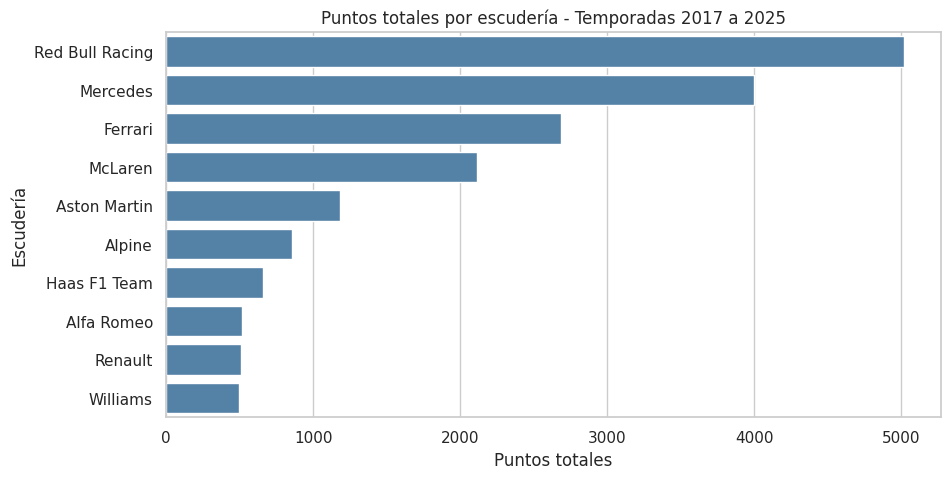

In [ ]:
top10 = kpi1.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top10.values, y=top10.index, color="steelblue")
plt.title("Puntos totales por escudería - Temporadas 2017 a 2025")
plt.xlabel("Puntos totales")
plt.ylabel("Escudería")
plt.show()

**Interpretación:** Red Bull Racing es la escudería con más puntos (5.021), seguida por Mercedes (3.996) y Ferrari (2.683). Las tres primeras suman más del 60 % de los puntos repartidos (11.700 de 19.308). Les siguen McLaren (2.113) y Aston Martin (1.184).

#### Gráfico 2: evolución de los puntos por temporada (KPI 1)

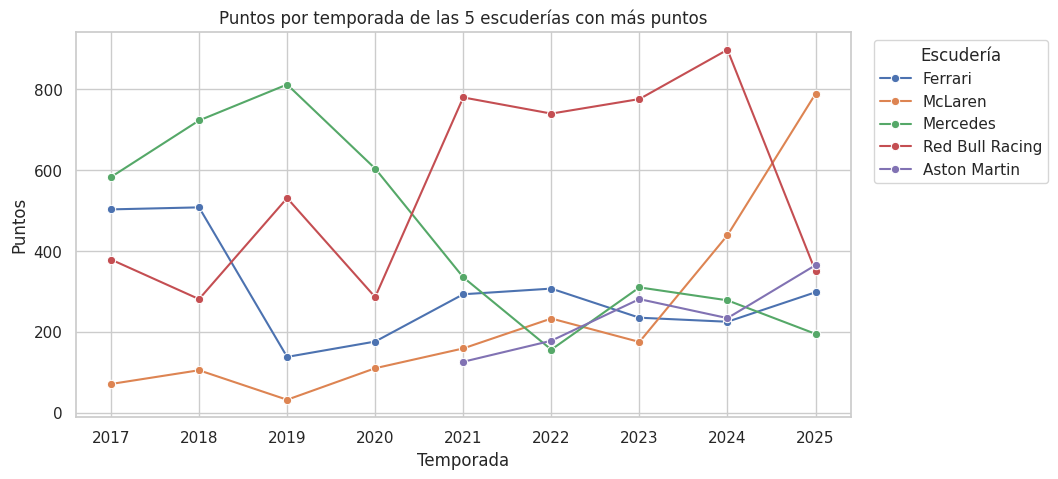

In [ ]:
top5 = kpi1.sort_values(ascending=False).head(5).index
puntos_temporada = resultados[resultados["escuderia"].isin(top5)].groupby(["temporada", "escuderia"])["puntos"].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=puntos_temporada, x="temporada", y="puntos", hue="escuderia", marker="o")
plt.title("Puntos por temporada de las 5 escuderías con más puntos")
plt.xlabel("Temporada")
plt.ylabel("Puntos")
plt.legend(title="Escudería", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Interpretación:** se ven cambios de liderazgo.
- Mercedes dominó de 2017 a 2020 (583, 723, 812 y 604 puntos) y después cayó a 335 en 2021 y 156 en 2022.
- Red Bull subió a 780 puntos en 2021 y se mantuvo arriba hasta 2024 (898 puntos), pero bajó a 350 en 2025.
- McLaren pasó de 71 puntos en 2017 a 789 en 2025, el valor más alto de esa temporada.
- Ferrari sumó unos 500 puntos en 2017 y 2018 y bajó a 138 en 2019.

#### Gráfico 3: porcentaje de abandonos por temporada (KPI 2)

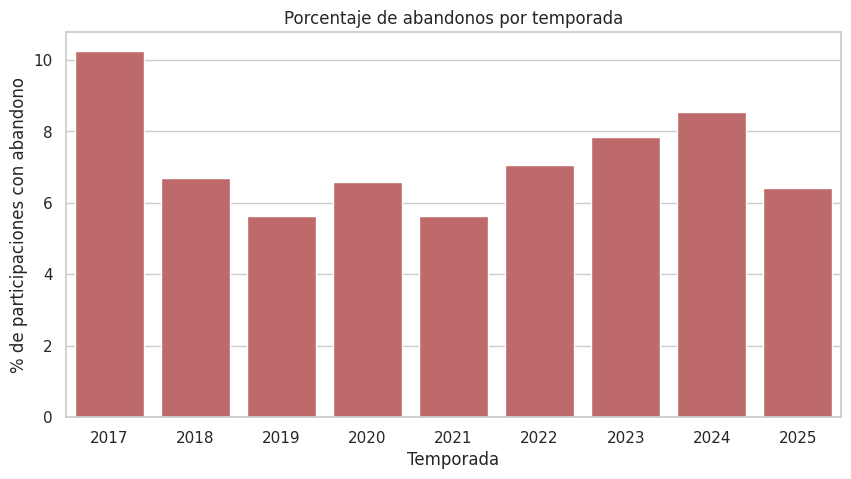

In [ ]:
abandonos_temporada = (resultados.groupby("temporada")["abandono"].mean() * 100).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=abandonos_temporada, x="temporada", y="abandono", color="indianred")
plt.title("Porcentaje de abandonos por temporada")
plt.xlabel("Temporada")
plt.ylabel("% de participaciones con abandono")
plt.show()

**Interpretación:** el porcentaje de abandonos es más alto en 2017 (10,3 %) y más bajo en 2019 (5,6 %). Después sube hasta 8,9 % en 2024 y baja a 6,6 % en 2025. El promedio de 2017 a 2019 (7,6 %) es casi igual al de 2023 a 2025 (7,9 %), así que **no se ve una tendencia clara** a lo largo de los años: los abandonos oscilan entre 5 % y 10 %.

#### Gráfico 4: posición de largada vs. posición final (KPI 3)

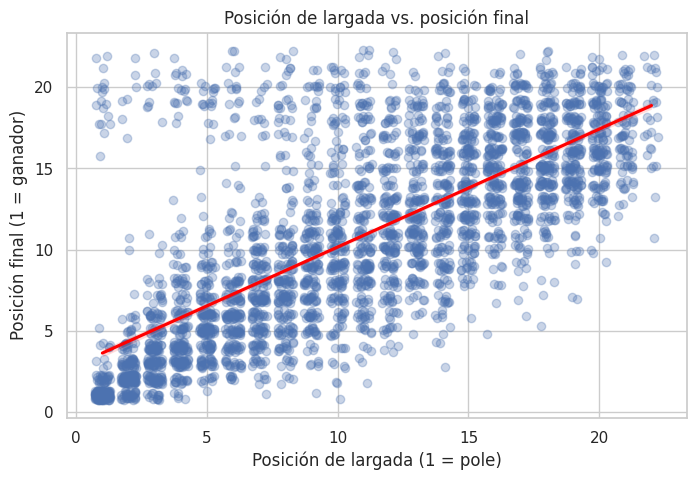

In [ ]:
plt.figure(figsize=(8, 5))
sns.regplot(data=resultados, x="posicion_largada", y="posicion_final",
            x_jitter=0.3, y_jitter=0.3, scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Posición de largada vs. posición final")
plt.xlabel("Posición de largada (1 = pole)")
plt.ylabel("Posición final (1 = ganador)")
plt.show()

**Interpretación:** la línea roja sube de izquierda a derecha: quien larga más atrás termina más atrás (correlación 0,72). La pole gana el 70,8 % de las veces y promedia 20,8 puntos. Quienes largan entre los 3 primeros promedian 16,7 puntos pero pierden en promedio 1,66 posiciones; quienes largan desde la 15.ª o peor suman solo 0,16 puntos, aunque ganan 2,15 posiciones en promedio, porque tienen más lugares para avanzar.

#### Gráfico 5: velocidad media según el clima

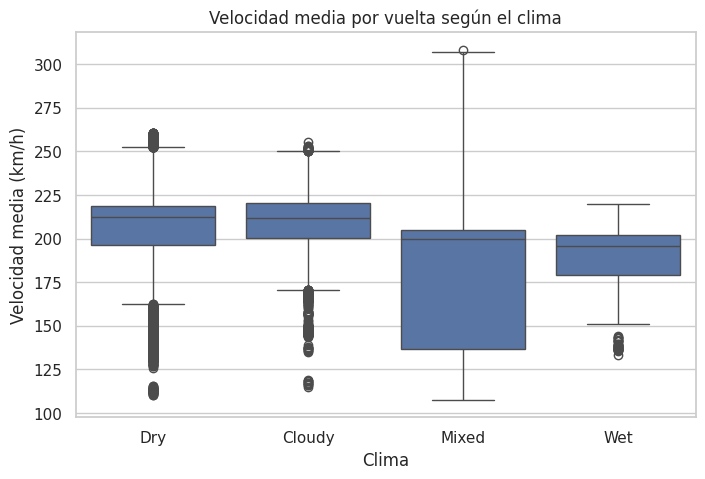

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data_set_limpio, x="clima", y="vel_media_kmh", order=["Dry", "Cloudy", "Mixed", "Wet"])
plt.title("Velocidad media por vuelta según el clima")
plt.xlabel("Clima")
plt.ylabel("Velocidad media (km/h)")
plt.show()

**Interpretación:** la velocidad media por vuelta es más baja con lluvia: la mediana es de 212,1 km/h en seco, 211,5 nublado, 199,7 con clima mixto y 195,3 con lluvia, es decir un 7,9 % menos que en seco. Las cajas son anchas porque en el gráfico se mezclan circuitos muy distintos (Mónaco y Monza no son comparables), así que conviene mirar la diferencia entre climas y no el valor absoluto.

## 7. Respuestas y conclusiones

**Pregunta principal: ¿cómo evolucionó el rendimiento de las escuderías entre 2017 y 2025 y qué factores se relacionan con los mejores resultados?**
El liderazgo cambió con los años: Mercedes dominó de 2017 a 2020, Red Bull de 2021 a 2024 y McLaren tuvo la mayor cantidad de puntos en 2025. Los abandonos no muestran una tendencia clara (entre 5,6 % y 10,3 % por temporada). Los factores que más se relacionan con los buenos resultados son la posición de largada (correlación de 0,72 con la posición final) y el clima: con lluvia la velocidad media baja un 7,9 %.

**KPI 1: ¿qué escuderías acumularon más puntos?**
Red Bull Racing (5.021), Mercedes (3.996) y Ferrari (2.683) suman más del 60 % de los puntos. Por temporada se ve la transición de Mercedes a Red Bull y de Red Bull a McLaren.

**KPI 2: ¿qué porcentaje de las participaciones terminó en abandono?**
El 7,5 % en total. Las escuderías con más abandonos son Racing Bulls (10,4 %), Ferrari (10,2 %) y Mercedes (9,9 %), pero son pocos casos por escudería y las diferencias son moderadas.

**KPI 3: ¿cuántas posiciones ganan o pierden y qué tanto influye la largada?**
Las escuderías que largan adelante (Ferrari -0,86, Mercedes -0,61) pierden posiciones en promedio y las que largan atrás (Sauber +1,58, Kick Sauber +0,89, RB +0,87) ganan. La largada influye mucho: la pole gana el 70,8 % de las carreras y promedia 20,8 puntos.

**Limitaciones:** los tiempos, posiciones, puntos y clima son datos sintéticos, así que los hallazgos describen este dataset y no la F1 real. Además, las escuderías que cambiaron de nombre (Force India, Racing Point y Aston Martin; Toro Rosso, AlphaTauri, RB y Racing Bulls; Sauber, Alfa Romeo y Kick Sauber) se analizaron por separado.